In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import sys
sys.path.append('../src')

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

# JAX imports
import jax
import optax
from flax import nnx
import grain

# Scikit-learn imports
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Custom imports
from jaxrl.models.cnn import CNN

In [3]:
# Data
DATA_DIR = "../data"

# Model
N_IN = 1 # gray scale
N_OUT = 10 # classes

# Hyperparameters
LR = 0.001 # learning rate
N_EPOCHS = 5
BATCH_SIZE = 64
EVAL_BATCH_SIZE = 1000 # divides the validation and test sets evenly
SEED = 0 # also seeds scikit-learn and Grain, which take integer seeds

# Random keys
main_key = jax.random.key(SEED)
main_key, model_key = jax.random.split(main_key)

## Data

In [4]:
# 70,000 images of 28x28 pixels, flattened (784,).
# Train set 60,000, test set 10,000.
X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=DATA_DIR)
X, y = X.astype(np.float32), y.astype(np.int32)

X_train_full, X_test = X[:60_000], X[60_000:]
y_train_full, y_test = y[:60_000], y[60_000:]

In [5]:
# Train/validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, 
    test_size=10_000, 
    stratify=y_train_full, # same proportion of classes
    random_state=SEED
)

In [6]:
# A single mean and std over all pixels, estimated on the training set only
scaler = StandardScaler().fit(X_train.reshape(-1, 1))

def preprocess(X):
    """Standardize flat images and reshape them to NHWC, shape (N, 28, 28, 1)."""
    X = scaler.transform(X.reshape(-1, 1))
    return X.reshape(-1, 28, 28, 1)

X_train = preprocess(X_train)
X_val = preprocess(X_val)
X_test = preprocess(X_test)

In [7]:
# Shuffle and batch indices, then gather each batch from the arrays in one step.
def build_train_dataset(X, y, seed):
    """Batches of (images, labels) in an order determined by the seed."""
    return (
        grain.MapDataset.range(len(X))
        .shuffle(seed=seed)
        .batch(BATCH_SIZE, drop_remainder=True)
        .map(lambda idx: (X[idx], y[idx]))
    )

def build_eval_dataset(X, y):
    """Batches of (images, labels) in a fixed order."""
    return (
        grain.MapDataset.range(len(X))
        .batch(EVAL_BATCH_SIZE)
        .map(lambda idx: (X[idx], y[idx]))
    )

val_ds = build_eval_dataset(X_val, y_val)
test_ds = build_eval_dataset(X_test, y_test)

## Model

In [8]:
model = CNN(
    n_in=N_IN,
    n_out=N_OUT,
    rngs=nnx.Rngs(model_key)
)

In [9]:
# nnx.display(model)

## Optimizer

In [10]:
optimizer = nnx.Optimizer(
    model,
    tx=optax.adam(learning_rate=LR),
    wrt=nnx.Param # only apply the updates wrt to variables with type nnx.Param
)

In [11]:
# Running loss and accuracy, accumulated on the device and read once per epoch
metrics = nnx.MultiMetric(
    accuracy=nnx.metrics.Accuracy(),
    loss=nnx.metrics.Average("loss"),
)

## Training

In [12]:
def loss_fn(model, x, y):
    """Mean cross-entropy over the batch; also returns the logits (batch_size, num_classes)."""
    # 1. Forward pass
    logits = model(x) # shape: (batch_size, num_classes)

    # 2. Compute the loss
    # optax computes -log(softmax(logits))[y] in one step
    nll = optax.softmax_cross_entropy_with_integer_labels(logits=logits, labels=y) # shape: (batch_size,)
    loss = nll.mean() # scalar
    return loss, logits

In [13]:
@nnx.jit
def train_step(model, optimizer, metrics, x, y):
    # 1-2. Forward pass, loss and gradients
    (loss, logits), grads = nnx.value_and_grad(loss_fn, has_aux=True)(model, x, y)
    # 3. Update the model parameters
    optimizer.update(model, grads)
    # 4. Accumulate loss and accuracy
    metrics.update(loss=loss, logits=logits, labels=y)

@nnx.jit
def eval_step(model, metrics, x, y):
    loss, logits = loss_fn(model, x, y)
    metrics.update(loss=loss, logits=logits, labels=y)

def train_epoch(model, optimizer, metrics, dataset):
    """One pass over the dataset; returns the loss and accuracy."""
    for x, y in dataset:
        train_step(model, optimizer, metrics, x, y)
    results = {name: float(value) for name, value in metrics.compute().items()}
    metrics.reset()
    return results

def evaluate(model, metrics, dataset):
    """One pass over the dataset; returns the loss and accuracy."""
    for x, y in dataset:
        eval_step(model, metrics, x, y)
    results = {name: float(value) for name, value in metrics.compute().items()}
    metrics.reset()
    return results

In [14]:
history = {
    'epoch': [],
    'train_loss': [], 'train_accuracy': [],
    'val_loss': [], 'val_accuracy': [],
}

time_start = time.time()
for epoch in range(1, N_EPOCHS + 1):
    # 1. Train, in a new order each epoch
    train_ds = build_train_dataset(X_train, y_train, seed=SEED + epoch)
    train_results = train_epoch(model, optimizer, metrics, train_ds)
    # 2. Evaluate on validation set
    val_results = evaluate(model, metrics, val_ds)

    history['epoch'].append(epoch)
    history['train_loss'].append(train_results['loss'])
    history['train_accuracy'].append(train_results['accuracy'])
    history['val_loss'].append(val_results['loss'])
    history['val_accuracy'].append(val_results['accuracy'])

    print(f"Epoch {epoch}: Train Loss: {train_results['loss']:.4f}, "
          f"Val Loss: {val_results['loss']:.4f}, Val Accuracy: {val_results['accuracy']:.4f}")

time_end = time.time()
print(f"Training time: {time_end - time_start:.2f} seconds")

Could not load symbol cuStreamGetGreenCtx. Error: /lib/x86_64-linux-gnu/libcuda.so.1: undefined symbol: cuStreamGetGreenCtx


Epoch 1: Train Loss: 0.1479, Val Loss: 0.0593, Val Accuracy: 0.9816
Epoch 2: Train Loss: 0.0495, Val Loss: 0.0443, Val Accuracy: 0.9863
Epoch 3: Train Loss: 0.0322, Val Loss: 0.0352, Val Accuracy: 0.9887
Epoch 4: Train Loss: 0.0231, Val Loss: 0.0446, Val Accuracy: 0.9860
Epoch 5: Train Loss: 0.0193, Val Loss: 0.0416, Val Accuracy: 0.9885
Training time: 14.98 seconds


In [15]:
# Save history as json
import json
with open("history.json", "w") as f:
    json.dump(history, f)

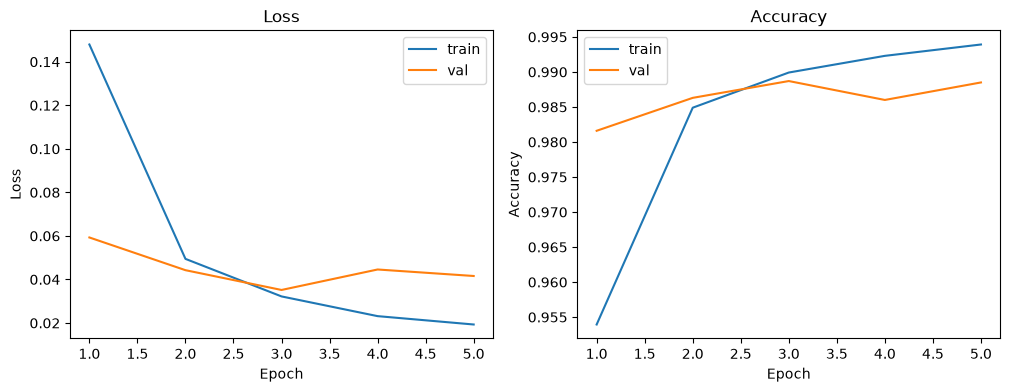

In [16]:
# Plot history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['epoch'], history[f'train_loss'], label='train')
axes[0].plot(history['epoch'], history[f'val_loss'], label='val')
axes[1].plot(history['epoch'], history[f'train_accuracy'], label='train')
axes[1].plot(history['epoch'], history[f'val_accuracy'], label='val')
axes[0].set(xlabel='Epoch', ylabel='Loss', title='Loss')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Accuracy')
axes[0].legend()
axes[1].legend()

In [17]:
test = evaluate(model, metrics, test_ds)
print(f"Test loss: {test['loss']:.4f}, Test accuracy: {test['accuracy'] * 100:.2f}%")

Test loss: 0.0430, Test accuracy: 98.65%
